In [15]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd
import networkx as nx
from collections import defaultdict

nodes_df = pd.read_csv('full_nodes.csv')
edges_df = pd.read_csv('full_edges.csv')

G = nx.Graph()

for _, row in nodes_df.iterrows():
    G.add_node(row['id'], label=row['label'], type=row.get('type', 'Unknown'))

for _, row in edges_df.iterrows():
    G.add_edge(row['source'], row['target'], interaction_type=row['interaction_type'], weight=row.get('weight', 1))

dna_dna_edges = [(u, v) for u, v, d in G.edges(data=True) if d['interaction_type'] == 'DNA-DNA']
dna_protein_edges = [(u, v) for u, v, d in G.edges(data=True) if d['interaction_type'] == 'DNA-Protein']

dna_to_proteins = defaultdict(set)
for u, v in dna_protein_edges:
    if G.nodes[u]['type'] == 'DNA' and G.nodes[v]['type'] == 'Protein':
        dna_to_proteins[u].add(v)
    elif G.nodes[v]['type'] == 'DNA' and G.nodes[u]['type'] == 'Protein':
        dna_to_proteins[v].add(u)

protein_protein_edges = [(u, v) for u, v, d in G.edges(data=True) if d['interaction_type'] == 'Protein-Protein']

G_protein = nx.Graph()
G_protein.add_edges_from(protein_protein_edges)

protein_nodes_in_dna_protein = set()
for u, v in dna_protein_edges:
    if G.nodes[u]['type'] == 'Protein':
        protein_nodes_in_dna_protein.add(u)
    elif G.nodes[v]['type'] == 'Protein':
        protein_nodes_in_dna_protein.add(v)

for protein in protein_nodes_in_dna_protein:
    if protein not in G_protein:
        G_protein.add_node(protein)

directly_mediated_loops = []
remaining_dna_dna_edges = []

for u, v in dna_dna_edges:
    proteins_u = dna_to_proteins.get(u, set())
    proteins_v = dna_to_proteins.get(v, set())
    common_proteins = proteins_u.intersection(proteins_v)
    if common_proteins:
        directly_mediated_loops.append((u, v, common_proteins))
    else:
        remaining_dna_dna_edges.append((u, v))

indirectly_mediated_loops = []
unmediated_loops = []

for u, v in remaining_dna_dna_edges:
    proteins_u = dna_to_proteins.get(u, set())
    proteins_v = dna_to_proteins.get(v, set())
    mediated = False
    for pu in proteins_u:
        for pv in proteins_v:
            if pu in G_protein and pv in G_protein:
                try:
                    if nx.has_path(G_protein, pu, pv):
                        mediated = True
                        break
                except nx.NodeNotFound:
                    continue
        if mediated:
            indirectly_mediated_loops.append((u, v))
            break
    if not mediated:
        unmediated_loops.append((u, v))

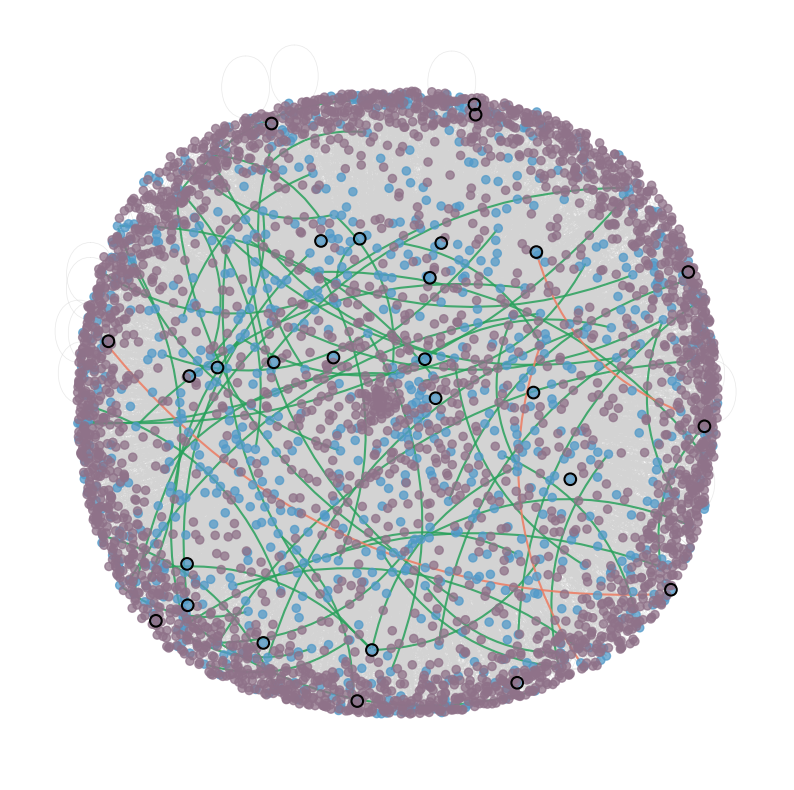

Total DNA-DNA interactions: 71
Directly mediated loops: 68
Indirectly mediated loops: 3
Unmediated loops: 0


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

dna_list = [ 
    'bin23', 'bin38', 'bin63', 'bin78', 'bin93', 'bin121', 'bin163', 'bin184',
    'bin209', 'bin236', 'bin253', 'bin283', 'bin328', 'bin375', 'bin426', 'bin447',
    'bin501', 'bin529', 'bin544', 'bin585', 'bin601', 'bin621', 'bin643', 'bin755',
    'bin791', 'bin856', 'bin871'
]

pos = nx.spring_layout(G, k=0.5, iterations=50)

plt.figure(figsize=(10, 10))
ax = plt.gca()

node_colors = []
for node in G.nodes():
    if G.nodes[node].get('type') == 'DNA':
        node_colors.append('#529ac9')
    elif G.nodes[node].get('type') == 'Protein':
        node_colors.append('#8f7289')
    else:
        node_colors.append('gray')

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=35, alpha=0.75)

highlight_nodes = [n for n in G.nodes() if n in dna_list]
nx.draw_networkx_nodes(
    G, pos,
    nodelist=highlight_nodes,
    node_color='None',
    edgecolors='black',
    linewidths=1.5,
    node_size=70,
    alpha=1
)

other_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('interaction_type') != 'DNA-DNA']
nx.draw_networkx_edges(G, pos, edgelist=other_edges, edge_color='lightgray', width=0.5, alpha=0.5)

def extract_edges(edges):
    return [(e[0], e[1]) if len(e) >= 2 else tuple(e) for e in edges]

direct_edges = extract_edges(directly_mediated_loops)
indirect_edges = extract_edges(indirectly_mediated_loops)
unmediated_edges = extract_edges(unmediated_loops)

def draw_curved_edges(edges, pos, ax, color, width, rad):
    for (u, v) in edges:
        if u not in pos or v not in pos:
            continue
        if u == v:
            x, y = pos[u]
            loop = FancyArrowPatch(
                (x, y), (x, y),
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle='-',
                linestyle='-',
                linewidth=width,
                color=color,
                alpha=1
            )
            ax.add_patch(loop)
        else:
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            curved_edge = FancyArrowPatch(
                (x1, y1), (x2, y2),
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle='-',
                linestyle='-',
                linewidth=width,
                color=color,
                alpha=0.85
            )
            ax.add_patch(curved_edge)

draw_curved_edges(direct_edges, pos, ax, color='#29a15c', width=1.5, rad=0.25)
draw_curved_edges(indirect_edges, pos, ax, color='#ed7b61', width=1.5, rad=-0.25)
nx.draw_networkx_edges(G, pos, edgelist=unmediated_edges, edge_color='gray', width=1, alpha=0.35)

legend_elements = [
    Line2D([0], [0], color='#29a15c', lw=2, label='Directly Mediated Loops'),
    Line2D([0], [0], color='#ed7b61', lw=2, label='Indirectly Mediated Loops'),
    Line2D([0], [0], color='gray', lw=2, label='Non-loop interactions'),
    Line2D([0], [0], marker='o', color='w', label='DNA', markerfacecolor='#529ac9', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Protein', markerfacecolor='#8f7289', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='CID boundary', markerfacecolor='#529ac9',
           markeredgecolor='black', markeredgewidth=1.5, markersize=10)
]

# title_text = '3D Genomic Loops and Protein Interactions in Mycobacterium tuberculosis'
# plt.title(title_text)
plt.axis('off')

# plt.legend(handles=legend_elements, loc='best', frameon=False)

plt.savefig('loops-network.png', dpi=600, bbox_inches='tight')
plt.show()

# fig_leg = plt.figure(figsize=(6.5, 1.0))
# fig_leg.legend(handles=legend_elements, loc='center', ncol=3, frameon=False)
# fig_leg.savefig('loops-legend.pdf', format='pdf', bbox_inches='tight')
# plt.close(fig_leg)

# fig_hdr = plt.figure(figsize=(8.5, 1.2))
# fig_hdr.text(0.5, 0.5, title_text, ha='center', va='center', fontsize=14)
# fig_hdr.savefig('loops-header.pdf', format='pdf', bbox_inches='tight')
# plt.close(fig_hdr)

print(f"Total DNA-DNA interactions: {len(dna_dna_edges)}")
print(f"Directly mediated loops: {len(direct_edges)}")
print(f"Indirectly mediated loops: {len(indirect_edges)}")
print(f"Unmediated loops: {len(unmediated_edges)}")


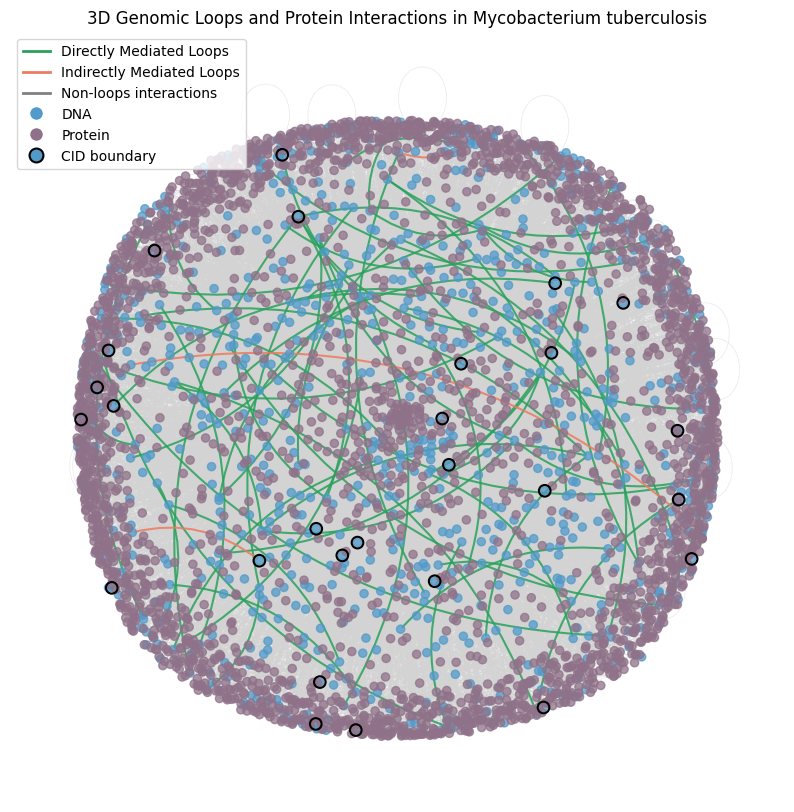

Total DNA-DNA interactions: 71
Directly mediated loops: 68
Indirectly mediated loops: 3
Unmediated loops: 0


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

# directly_mediated_loops, indirectly_mediated_loops, unmediated_loops, dna_dna_edges

dna_list = [ 
    'bin23', 'bin38', 'bin63', 'bin78', 'bin93', 'bin121', 'bin163', 'bin184',
    'bin209', 'bin236', 'bin253', 'bin283', 'bin328', 'bin375', 'bin426', 'bin447',
    'bin501', 'bin529', 'bin544', 'bin585', 'bin601', 'bin621', 'bin643', 'bin755',
    'bin791', 'bin856', 'bin871'
]

pos = nx.spring_layout(G, k=0.5, iterations=50)

plt.figure(figsize=(10, 10))
ax = plt.gca()

node_colors = []
for node in G.nodes():
    if G.nodes[node]['type'] == 'DNA':
        node_colors.append('#529ac9')
    elif G.nodes[node]['type'] == 'Protein':
        node_colors.append('#8f7289')
    else:
        node_colors.append('gray')

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=35, alpha=0.75)

highlight_nodes = [n for n in G.nodes() if n in dna_list]
nx.draw_networkx_nodes(
    G, pos,
    nodelist=highlight_nodes,
    node_color='None',       
    edgecolors='black',      
    linewidths=1.5,          
    node_size=70,            
    alpha=1
)

other_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('interaction_type') != 'DNA-DNA']
nx.draw_networkx_edges(G, pos, edgelist=other_edges, edge_color='lightgray', width=0.5, alpha=0.5)

def extract_edges(edges):
    """根据长度提取 (u, v) 对"""
    return [(u, v) if len(edge) == 2 else (edge[0], edge[1]) for edge in edges]

direct_edges = extract_edges(directly_mediated_loops)
# indirect_edges = extract_edges(indirectly_mediated_loops)
indirect_edges = indirectly_mediated_loops
unmediated_edges = extract_edges(unmediated_loops)

def draw_curved_edges(edges, pos, ax, color, width, rad):
    for (u, v) in edges:
        if u == v:
            x, y = pos[u]
            loop = FancyArrowPatch(
                (x, y),
                (x, y),
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle='-',
                linestyle='-',
                linewidth=width,
                color=color,
                alpha=1
            )
            ax.add_patch(loop)
        else:
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            curved_edge = FancyArrowPatch(
                (x1, y1),
                (x2, y2),
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle='-',
                linestyle='-',
                linewidth=width,
                color=color,
                alpha=0.85
            )
            ax.add_patch(curved_edge)

draw_curved_edges(direct_edges, pos, ax, color='#29a15c', width=1.5, rad=0.25)

draw_curved_edges(indirect_edges, pos, ax, color='#ed7b61', width=1.5, rad=-0.25)

nx.draw_networkx_edges(
    G, pos,
    edgelist=unmediated_edges,
    edge_color='gray',
    width=1,
    alpha=0.35,
    label='Unmediated'
)

legend_elements = [
    Line2D([0], [0], color='#29a15c', lw=2, label='Directly Mediated Loops'),
    Line2D([0], [0], color='#ed7b61', lw=2, label='Indirectly Mediated Loops'),
    Line2D([0], [0], color='gray', lw=2, label='Non-loops interactions'),
    Line2D([0], [0], marker='o', color='w', label='DNA', markerfacecolor='#529ac9', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Protein', markerfacecolor='#8f7289', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='CID boundary', markerfacecolor='#529ac9', 
           markeredgecolor='black', markeredgewidth=1.5, markersize=10)
]

plt.legend(handles=legend_elements, loc='best')

plt.title('3D Genomic Loops and Protein Interactions in Mycobacterium tuberculosis')
plt.axis('off')
plt.savefig('loops-network.pdf', format='pdf')
plt.show()

print(f"Total DNA-DNA interactions: {len(dna_dna_edges)}")
print(f"Directly mediated loops: {len(direct_edges)}")
print(f"Indirectly mediated loops: {len(indirect_edges)}")
print(f"Unmediated loops: {len(unmediated_edges)}")

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D


dna_list = [ 
    'bin23', 'bin38', 'bin63', 'bin78', 'bin93', 'bin121', 'bin163', 'bin184',
    'bin209', 'bin236', 'bin253', 'bin283', 'bin328', 'bin375', 'bin426', 'bin447',
    'bin501', 'bin529', 'bin544', 'bin585', 'bin601', 'bin621', 'bin643', 'bin755',
    'bin791', 'bin856', 'bin871'
]

pos = nx.spring_layout(G, k=0.5, iterations=50)

plt.figure(figsize=(10, 10),dpi=1200)
ax = plt.gca()

node_colors = []
for node in G.nodes():
    if G.nodes[node]['type'] == 'DNA':
        node_colors.append('#529ac9')  
    elif G.nodes[node]['type'] == 'Protein':
        node_colors.append('#8f7289')  
    else:
        node_colors.append('gray')

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=35, alpha=0.75)

highlight_nodes = [n for n in G.nodes() if n in dna_list]
nx.draw_networkx_nodes(
    G, pos,
    nodelist=highlight_nodes,
    node_color='None',       
    edgecolors='black',      
    linewidths=1.5,          
    node_size=70,           
    alpha=1
)

other_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('interaction_type') != 'DNA-DNA']
nx.draw_networkx_edges(G, pos, edgelist=other_edges, edge_color='lightgray', width=0.5, alpha=0.5)

def extract_edges(edges):
    """根据长度提取 (u, v) 对"""
    return [(u, v) if len(edge) == 2 else (edge[0], edge[1]) for edge in edges]

direct_edges = extract_edges(directly_mediated_loops)
# indirect_edges = extract_edges(indirectly_mediated_loops)
indirect_edges = indirectly_mediated_loops
unmediated_edges = extract_edges(unmediated_loops)

def draw_curved_edges(edges, pos, ax, color, width, rad):
    for (u, v) in edges:
        if u == v:
            x, y = pos[u]
            loop = FancyArrowPatch(
                (x, y),
                (x, y),
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle='-',
                linestyle='-',
                linewidth=width,
                color=color,
                alpha=1
            )
            ax.add_patch(loop)
        else:
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            curved_edge = FancyArrowPatch(
                (x1, y1),
                (x2, y2),
                connectionstyle=f"arc3,rad={rad}",
                arrowstyle='-',
                linestyle='-',
                linewidth=width,
                color=color,
                alpha=0.85
            )
            ax.add_patch(curved_edge)

draw_curved_edges(direct_edges, pos, ax, color='#29a15c', width=1.5, rad=0.25)

draw_curved_edges(indirect_edges, pos, ax, color='#ed7b61', width=1.5, rad=-0.25)

nx.draw_networkx_edges(
    G, pos,
    edgelist=unmediated_edges,
    edge_color='gray',
    width=1,
    alpha=0.35,
    label='Unmediated'
)

legend_elements = [
    Line2D([0], [0], color='#29a15c', lw=2, label='Directly Mediated Loops'),
    Line2D([0], [0], color='#ed7b61', lw=2, label='Indirectly Mediated Loops'),
    Line2D([0], [0], color='gray', lw=2, label='Non-loops interactions'),
    Line2D([0], [0], marker='o', color='w', label='DNA', markerfacecolor='#529ac9', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Protein', markerfacecolor='#8f7289', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='CID boundary', markerfacecolor='#529ac9', 
           markeredgecolor='black', markeredgewidth=1.5, markersize=10)
]

plt.legend(handles=legend_elements, loc='best')

plt.title('3D Genomic Loops and Protein Interactions in Mycobacterium tuberculosis')
plt.axis('off')
plt.savefig('loops-network.png', format='png')
plt.show()

print(f"Total DNA-DNA interactions: {len(dna_dna_edges)}")
print(f"Directly mediated loops: {len(direct_edges)}")
print(f"Indirectly mediated loops: {len(indirect_edges)}")
print(f"Unmediated loops: {len(unmediated_edges)}")

Total DNA-DNA interactions: 71
Directly mediated loops: 68
Indirectly mediated loops: 3
Unmediated loops: 0


In [ ]:
direct_mediation_results = []

for u, v, common_proteins in directly_mediated_loops:
    for protein in common_proteins:
        direct_mediation_results.append({
            'Protein': protein,
            'DNA1': u,
            'DNA2': v
        })

direct_mediation_df = pd.DataFrame(direct_mediation_results)

# direct_mediation_df.to_csv('directly_mediated_protein_results.csv', index=False)

# 显示结果
print(direct_mediation_df)

     Protein    DNA1    DNA2
0     Rv0678   bin34   bin41
1       kstR   bin34   bin41
2    Rv1776c   bin34   bin41
3    Rv2250c   bin34   bin41
4     Rv0324   bin34   bin41
..       ...     ...     ...
295     whiA  bin832  bin839
296  Rv2250c  bin832  bin839
297  Rv0767c  bin848  bin855
298   Rv3736  bin848  bin855
299   Rv1816  bin848  bin855

[300 rows x 3 columns]


In [39]:
# import matplotlib as mpl
# import matplotlib.pyplot as plt
# mpl.rcParams['pdf.fonttype'] = 42
# mpl.rcParams['ps.fonttype'] = 42
# plt.rcParams['svg.fonttype'] = 'none'

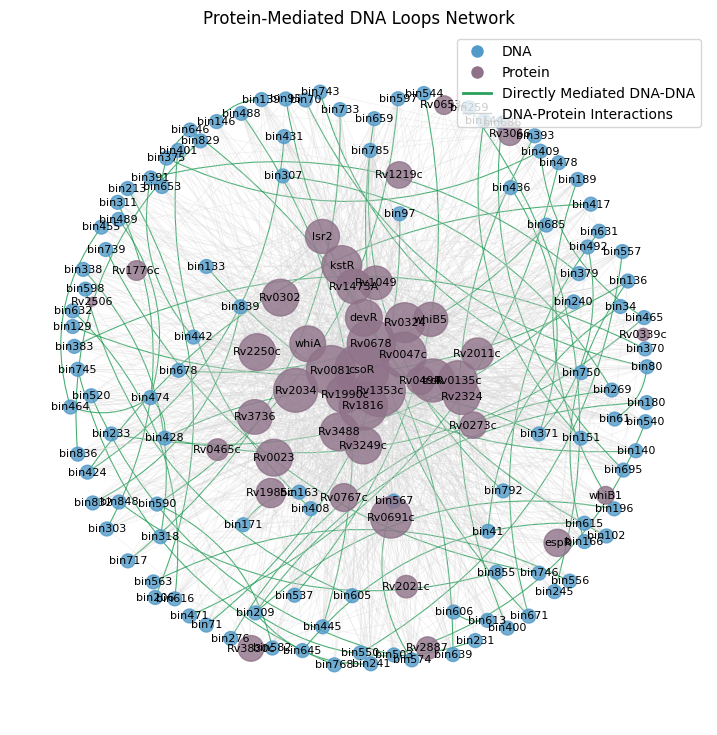

In [ ]:
dna_nodes = set()
protein_nodes = set()

for u, v, common_proteins in directly_mediated_loops:
    dna_nodes.add(u)
    dna_nodes.add(v)
    protein_nodes.update(common_proteins)

sub_dna_protein_edges = []
for u, v in dna_protein_edges:
    if (u in dna_nodes and v in protein_nodes) or (v in dna_nodes and u in protein_nodes):
        sub_dna_protein_edges.append((u, v))

sub_dna_dna_edges = [(u, v) for u, v, _ in directly_mediated_loops]

G_sub = nx.Graph()

for node in dna_nodes:
    G_sub.add_node(node, **G.nodes[node])

for node in protein_nodes:
    G_sub.add_node(node, **G.nodes[node])

for u, v in sub_dna_protein_edges:
    G_sub.add_edge(u, v, **G.edges[u, v])

for u, v in sub_dna_dna_edges:
    G_sub.add_edge(u, v, **G.edges[u, v])

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

pos = nx.spring_layout(G_sub, k=3, iterations=100)

plt.figure(figsize=(9, 9))
ax = plt.gca()

node_colors = []
node_sizes = []

for node in G_sub.nodes():
    if G_sub.nodes[node]['type'] == 'DNA':
        node_colors.append('#529ac9')  
        node_sizes.append(100) 
    elif G_sub.nodes[node]['type'] == 'Protein':
        node_colors.append('#8f7289')  
        node_degree = G_sub.degree(node)
        node_sizes.append(node_degree * 20)
    else:
        node_colors.append('gray')
        node_sizes.append(100)

nx.draw_networkx_nodes(G_sub, pos, node_color=node_colors, node_size=node_sizes, alpha=0.8)

def draw_curved_edges(edges, pos, ax, color, width, rad):
    for (u, v) in edges:
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        curved_edge = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            connectionstyle=f"arc3,rad={rad}",
            arrowstyle='-',
            linestyle='-',
            linewidth=width,
            color=color,
            alpha=0.85
        )
        ax.add_patch(curved_edge)

draw_curved_edges(sub_dna_dna_edges, pos, ax, color='#29a15c', width=0.8, rad=0.25)

nx.draw_networkx_edges(
    G_sub, pos, edgelist=sub_dna_protein_edges, edge_color='lightgray', 
    width=0.5, alpha=0.35, label='DNA-Protein Interactions'
)

labels = {node: node for node in G_sub.nodes()}
nx.draw_networkx_labels(G_sub, pos, labels=labels, font_size=8)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='DNA', markerfacecolor='#529ac9', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Protein', markerfacecolor='#8f7289', markersize=10),
    Line2D([0], [0], color='#29a15c', lw=2, label='Directly Mediated DNA-DNA'),
    Line2D([0], [0], color='lightgray', lw=1, label='DNA-Protein Interactions')
]
plt.legend(handles=legend_elements, loc='upper right')

plt.title('Protein-Mediated DNA Loops Network')
plt.axis('off')
plt.savefig('zoomed_in_network.pdf', format='pdf')
plt.show()

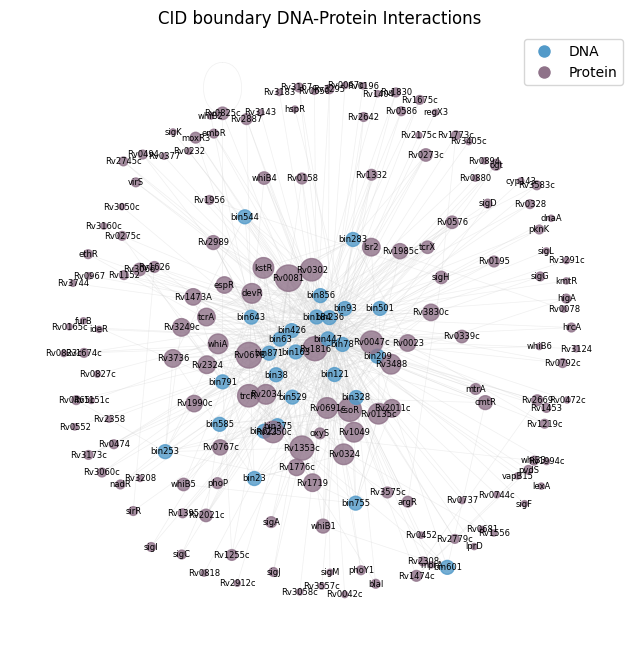

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D
from collections import Counter

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'

dna_list = [ 
    'bin23', 'bin38', 'bin63', 'bin78', 'bin93', 'bin121', 'bin163', 'bin184',
    'bin209', 'bin236', 'bin253', 'bin283', 'bin328', 'bin375', 'bin426', 'bin447',
    'bin501', 'bin529', 'bin544', 'bin585', 'bin601', 'bin621', 'bin643', 'bin755',
    'bin791', 'bin856', 'bin871'
]

dna_list_in_G = [n for n in dna_list if n in G.nodes()]

protein_nodes = set()
for dna_node in dna_list_in_G:
    for neighbor in G.neighbors(dna_node):
        if G.nodes[neighbor].get('type') == 'Protein':
            protein_nodes.add(neighbor)

sub_nodes = set(dna_list_in_G) | protein_nodes

G_sub = G.subgraph(sub_nodes).copy()

pos = nx.spring_layout(G_sub, k=0.75, iterations=50)

plt.figure(figsize=(8, 8))

node_colors = []
node_sizes = []

for node in G_sub.nodes():
    if G_sub.nodes[node]['type'] == 'DNA':
        node_colors.append('#529ac9')  
        node_sizes.append(100)  
    elif G_sub.nodes[node]['type'] == 'Protein':
        node_colors.append('#8f7289')  
        node_degree = G_sub.degree(node)
        node_sizes.append(node_degree * 20) 
    else:
        node_colors.append('gray')
        node_sizes.append(100)

nx.draw_networkx_nodes(G_sub, pos, node_color=node_colors, node_size=node_sizes, alpha=0.8)

nx.draw_networkx_edges(
    G_sub, pos, edge_color='lightgray', width=0.5, alpha=0.35
)

labels = {node: node for node in G_sub.nodes()}
nx.draw_networkx_labels(G_sub, pos, labels=labels, font_size=6)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='DNA', markerfacecolor='#529ac9', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Protein', markerfacecolor='#8f7289', markersize=10)
]
plt.legend(handles=legend_elements, loc='best')

plt.title('CID boundary DNA-Protein Interactions')
plt.axis('off')
plt.savefig('CIDs_boundary_network.pdf', format='pdf')
plt.show()

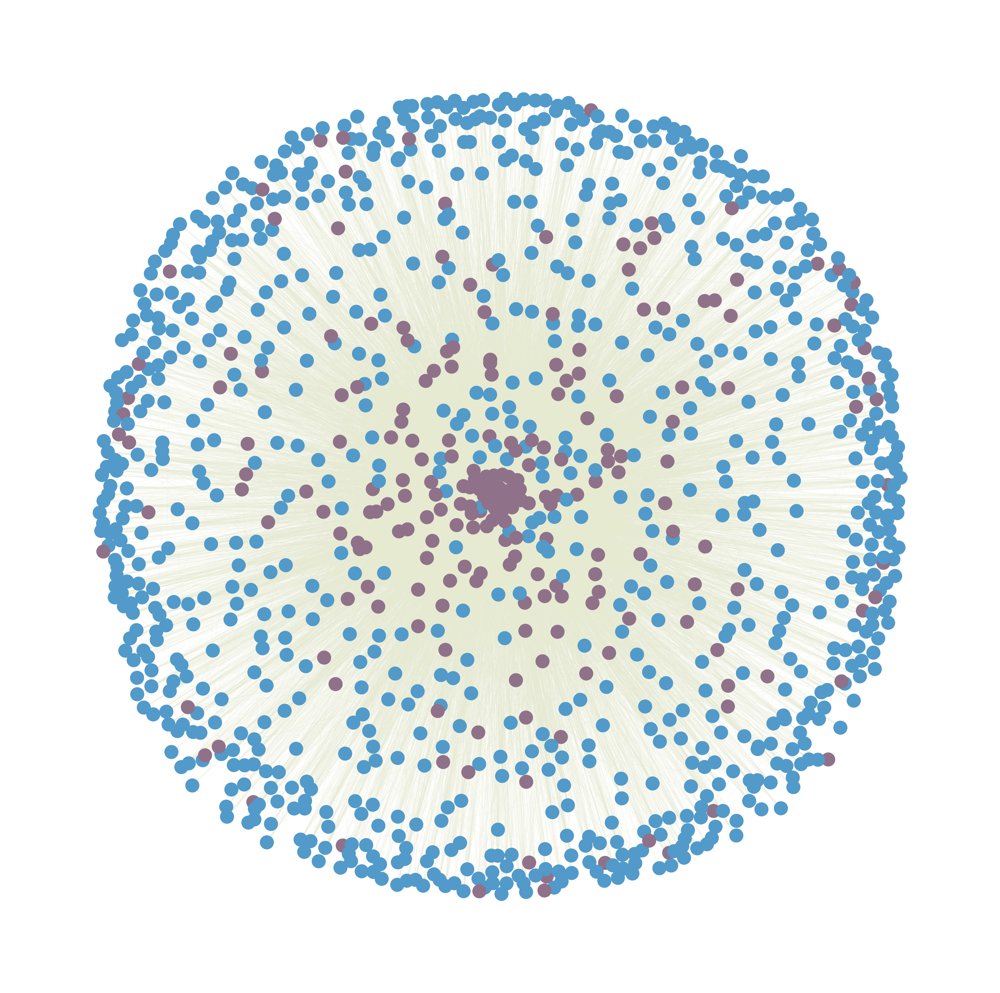

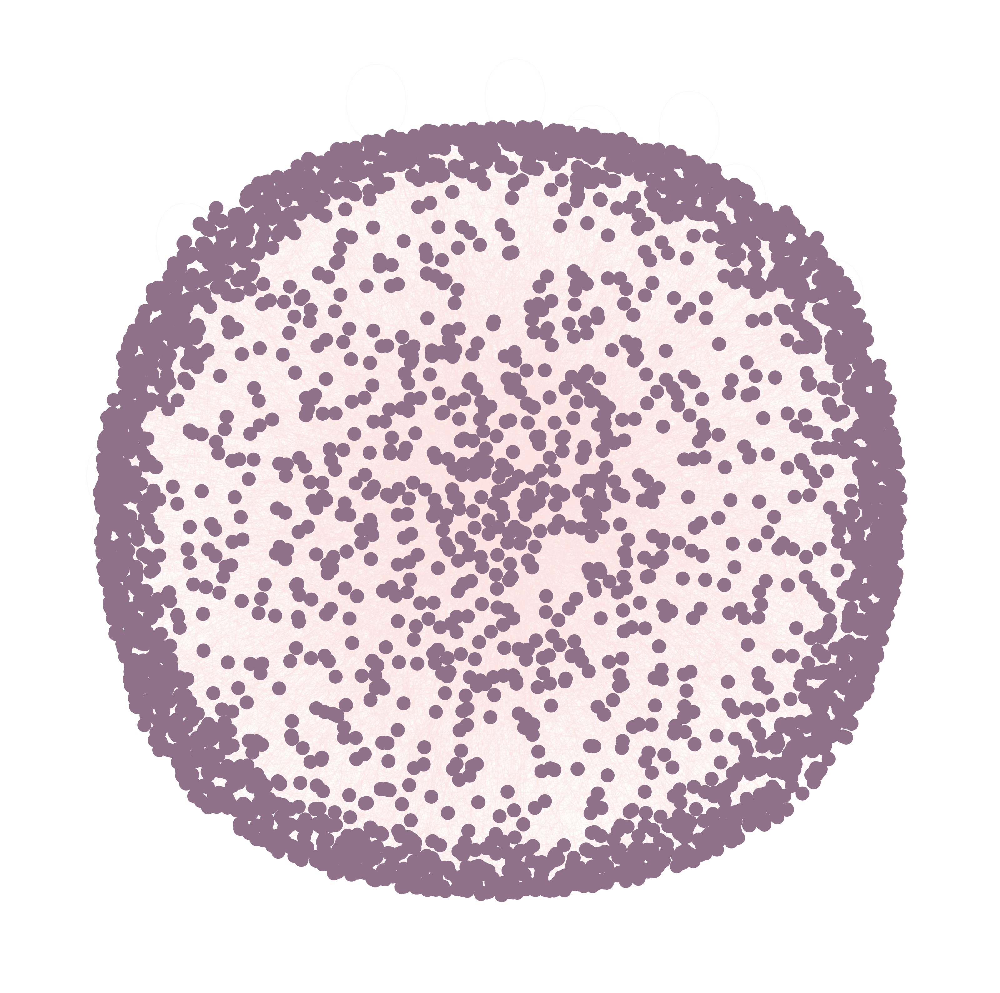

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

nodes_df = pd.read_csv('full_nodes.csv')
edges_df = pd.read_csv('full_edges.csv')

node_dict = nodes_df.set_index('id').to_dict('index')

def build_and_draw_subgraph(edge_type, edge_color, title, k, output):
    sub_edges_df = edges_df[edges_df['interaction_type'] == edge_type]
    
    sub_nodes = set(sub_edges_df['source']).union(set(sub_edges_df['target']))
    
    G_sub = nx.Graph()
    
    for node in sub_nodes:
        if node in node_dict:
            node_attr = node_dict[node]
            G_sub.add_node(node, **node_attr)
        else:
            G_sub.add_node(node, type='Unknown')
    
    for _, row in sub_edges_df.iterrows():
        G_sub.add_edge(row['source'], row['target'], 
        interaction_type=row['interaction_type'], weight=row['weight'])
    
    # G_sub.remove_nodes_from(list(nx.isolates(G_sub)))
    
    plt.figure(figsize=(8, 8),dpi=500)
    pos = nx.spring_layout(G_sub, k=k, iterations=50)

    node_colors = ['#529ac9' if G_sub.nodes[node].get('type') == 'DNA' else 
                   '#8f7289' if G_sub.nodes[node].get('type') == 'Protein' else 
                   'gray' for node in G_sub.nodes()]
    
    nx.draw_networkx_nodes(G_sub, pos, node_color=node_colors, node_size=30, alpha=1)
    nx.draw_networkx_edges(G_sub, pos, edge_color=edge_color, alpha=0.25, width=0.25)
    
    # nx.draw_networkx_labels(G_sub, pos, labels={node: node for node in G_sub.nodes()}, font_size=8)
    
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', label='DNA', markerfacecolor='#529ac9', markersize=10),
        plt.Line2D([0], [0], marker='o', color='w', label='Protein', markerfacecolor='#8f7289', markersize=10),
        plt.Line2D([0], [0], color=edge_color, lw=2, label=f'Edges: {edge_type}')
    ]
    # plt.legend(handles=legend_elements, loc='best')
    plt.savefig(f'{output}.png', format='png')
    # plt.title(title)
    plt.axis('off')
    plt.show()

# build_and_draw_subgraph('DNA-DNA', 'green', 'Subnetwork: DNA-DNA Interactions', k=0.25, output='DNA-DNA_subnetwork')
build_and_draw_subgraph('DNA-Protein', '#e6ead1', 
                        'Subnetwork: DNA-Protein Interactions',
                        k=0.8,output='DNA-Protein_subnetwork')
build_and_draw_subgraph('Protein-Protein', '#fce2e1', 
                        'Subnetwork: Protein-Protein Interactions',
                        k=0.5,output='Protein-Protein_subnetwork')